In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variants = [
	'gcamp',
	'gfp',
]
model_variant = 'ss'
organism = 'worm-2025-fieseler'

In [4]:
if 'gcamp' in data_variants:
	file_ids_gcamp = list(range(0, 33+1))
	# file_ids_gcamp = [19]

	path_gcamp = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
	filenames_gcamp = [read_utils.get_filename(read_utils.get_file_handle(path_gcamp, file_id)) for file_id in file_ids_gcamp]

if 'gfp' in data_variants:
	file_ids_gfp = list(range(0, 7+1))
	# file_ids_gfp = [2]

	path_gfp = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	filenames_gfp = [read_utils.get_filename(read_utils.get_file_handle(path_gfp, file_id)) for file_id in file_ids_gfp]

In [5]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

if 'gcamp' in data_variants:
	bom_folder_gcamp = (f'{'gcamp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gcamp = (f'{'gcamp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

if 'gfp' in data_variants:
	bom_folder_gfp = (f'{'gfp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gfp = (f'{'gfp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
if 'gcamp' in data_variants:
	boms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gcamp), filename)[0] for filename in filenames_gcamp]
	hgms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gcamp), filename)[0] for filename in filenames_gcamp]

if 'gfp' in data_variants:
	boms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gfp), filename)[0] for filename in filenames_gfp]
	hgms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gfp), filename)[0] for filename in filenames_gfp]

In [8]:
if 'gcamp' in data_variants:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

if 'gfp' in data_variants:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

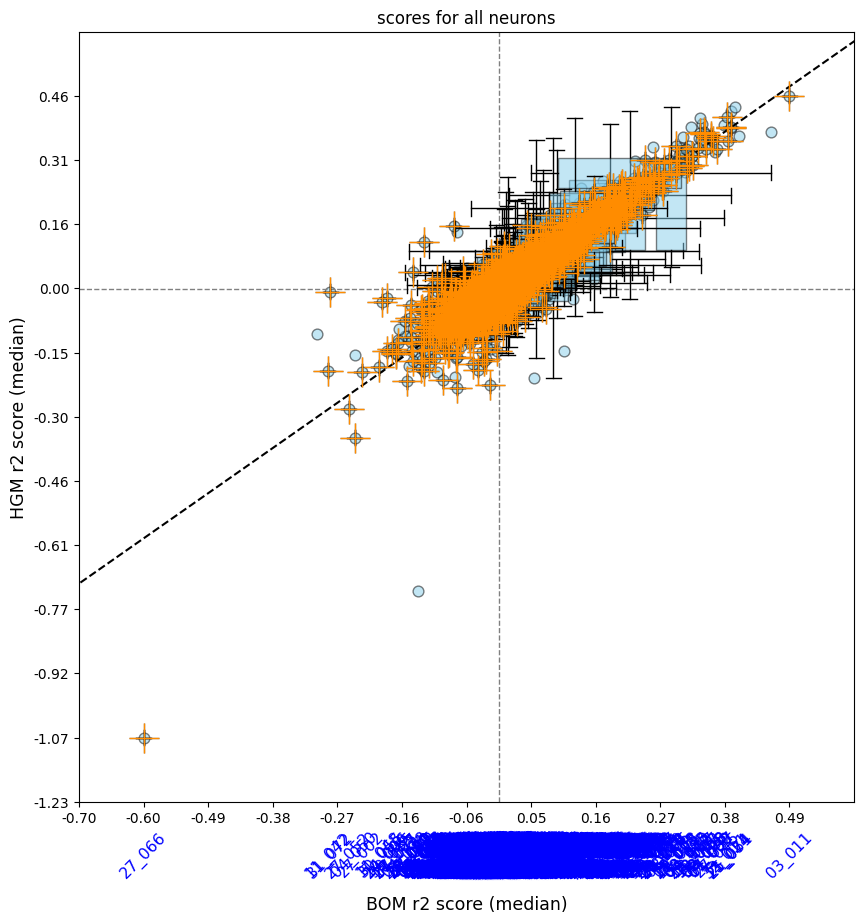

In [9]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, None,
		title='scores for all neurons', limits=None, force_medians=True
	)

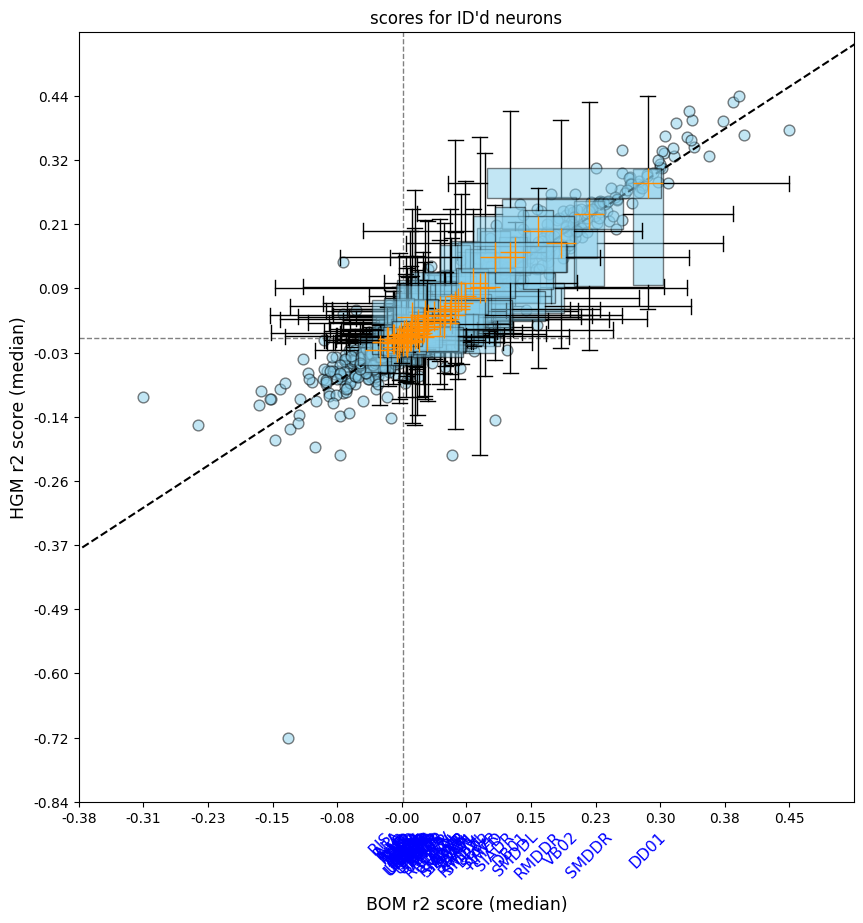

In [10]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=None
	)

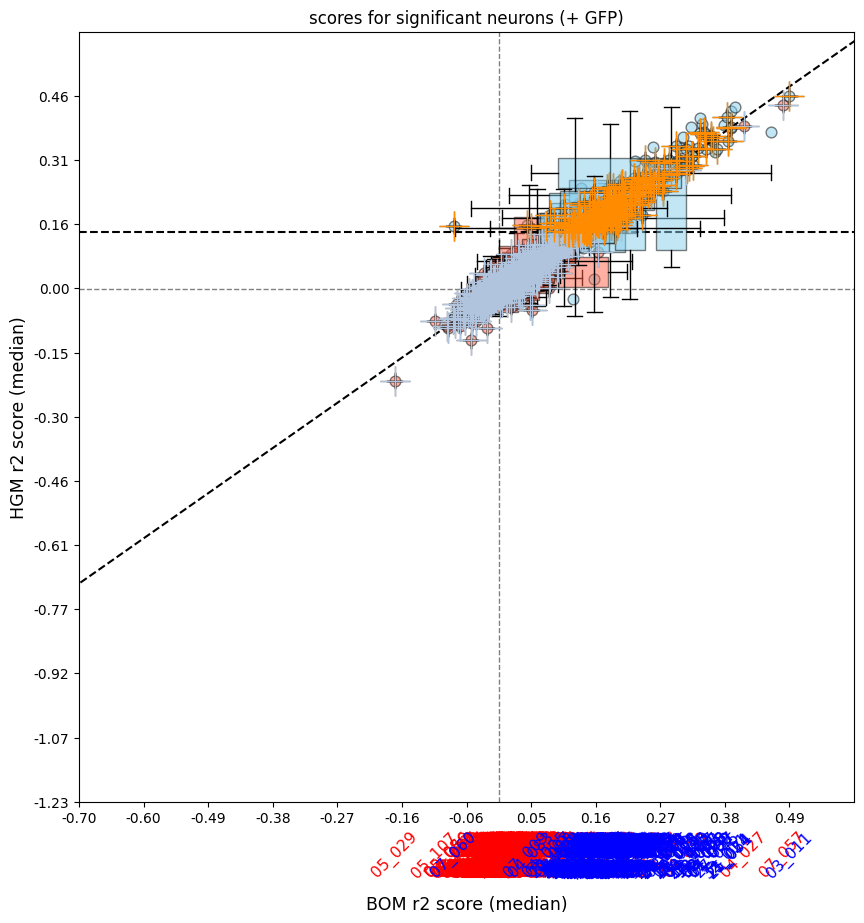

In [11]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, neuron_scores_gfp,
		title='scores for significant neurons (+ GFP)', limits=None, force_medians=True
	)

In [12]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
	threshold_bom_gfp = np.quantile(np.concatenate([pair[0] for pair in neuron_scores_gfp.values()]), 0.95)
	threshold_bom_gfp = np.array(0)

	neuron_scores_gcamp_hgm_sig = list(reversed(sorted({key: value for key, value in neuron_scores_gcamp.items() if np.median(value[1].reshape(-1, 1)) > threshold_hgm_gfp and np.median(value[0].reshape(-1, 1)) > threshold_bom_gfp}.items(), key=lambda x: np.median(x[1][1]))))
	neuron_scores_gcamp_hgm_sig_labels = list([val[0] for val in neuron_scores_gcamp_hgm_sig])

	print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_gcamp_hgm_sig if not key[0].isdigit()]))

NEURON: DD01,		HGMSCR: 0.2793
NEURON: SMDDR,		HGMSCR: 0.2249
NEURON: RMDDR,		HGMSCR: 0.1939
NEURON: VB02,		HGMSCR: 0.1718
NEURON: SMDDL,		HGMSCR: 0.1557
NEURON: SIADR,		HGMSCR: 0.1462
NEURON: DB01,		HGMSCR: 0.1460


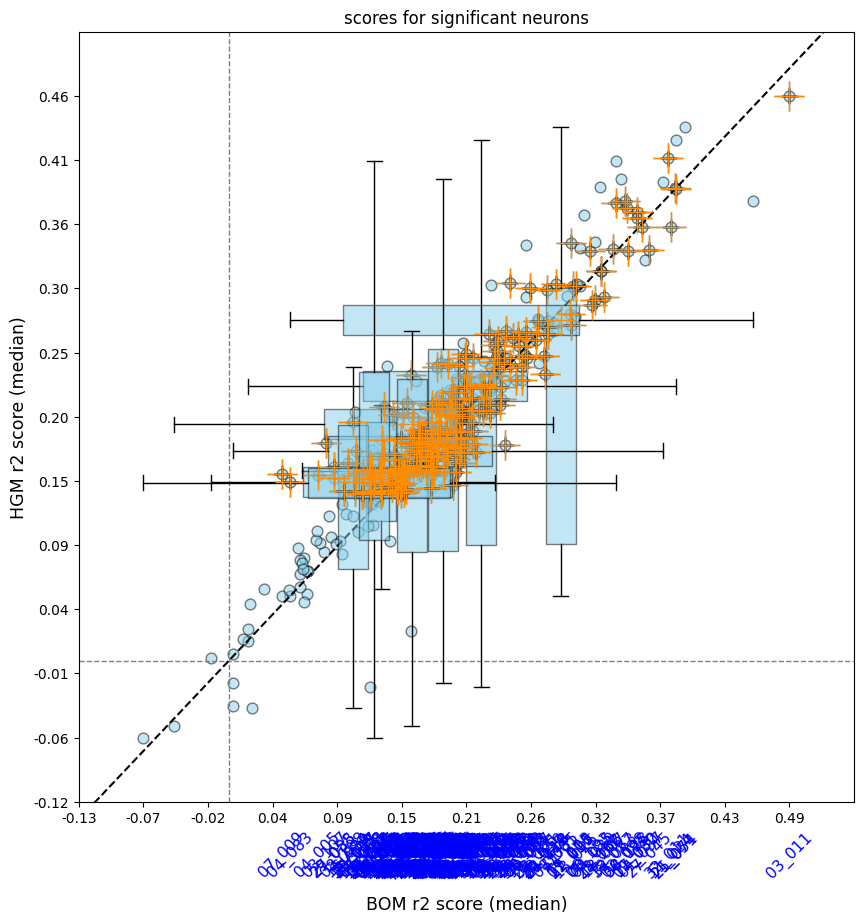

In [13]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp_hgm_sig_labels}, None,
		title='scores for significant neurons', limits=None, force_medians=True
	)

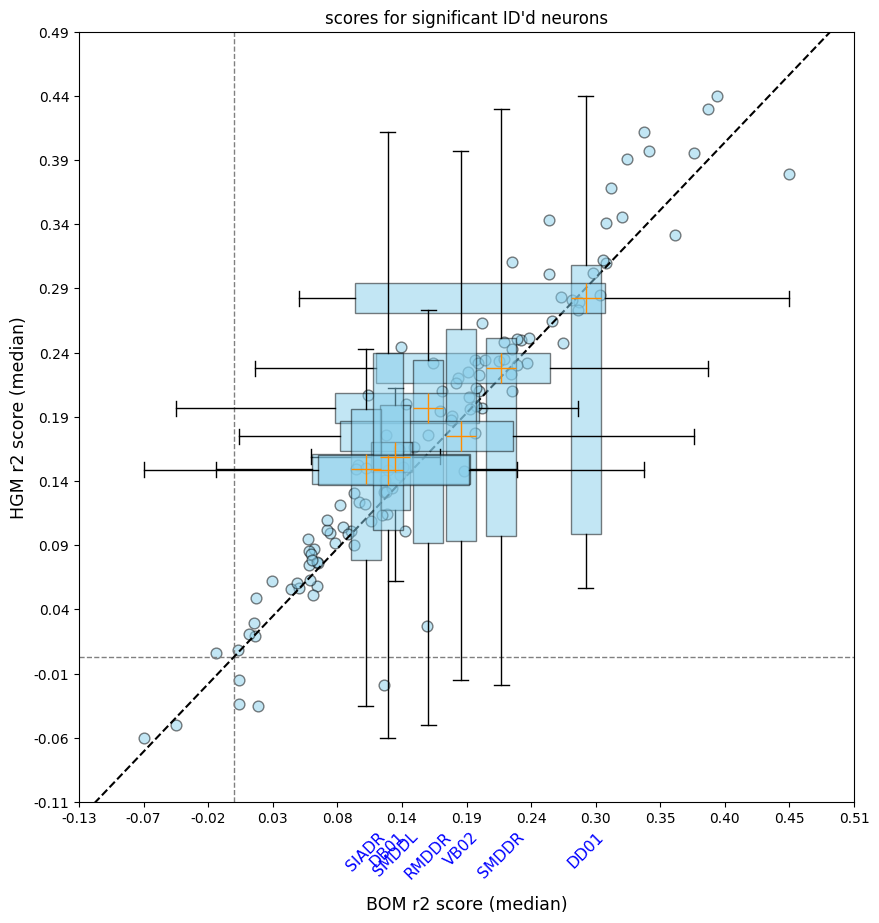

In [14]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp_hgm_sig_labels if not key[0].isdigit()}, None,
		title='scores for significant ID\'d neurons', limits=None
	)

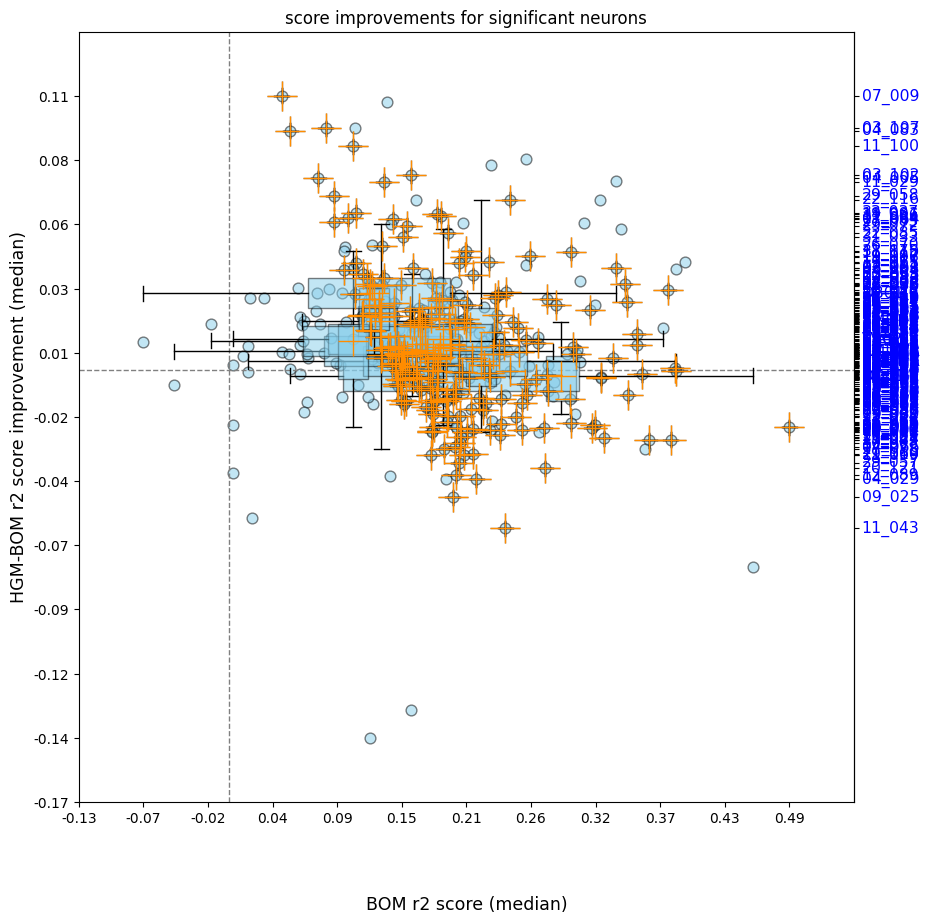

In [15]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp_hgm_sig_labels},
		title='score improvements for significant neurons', limits=None, force_medians=True
	)

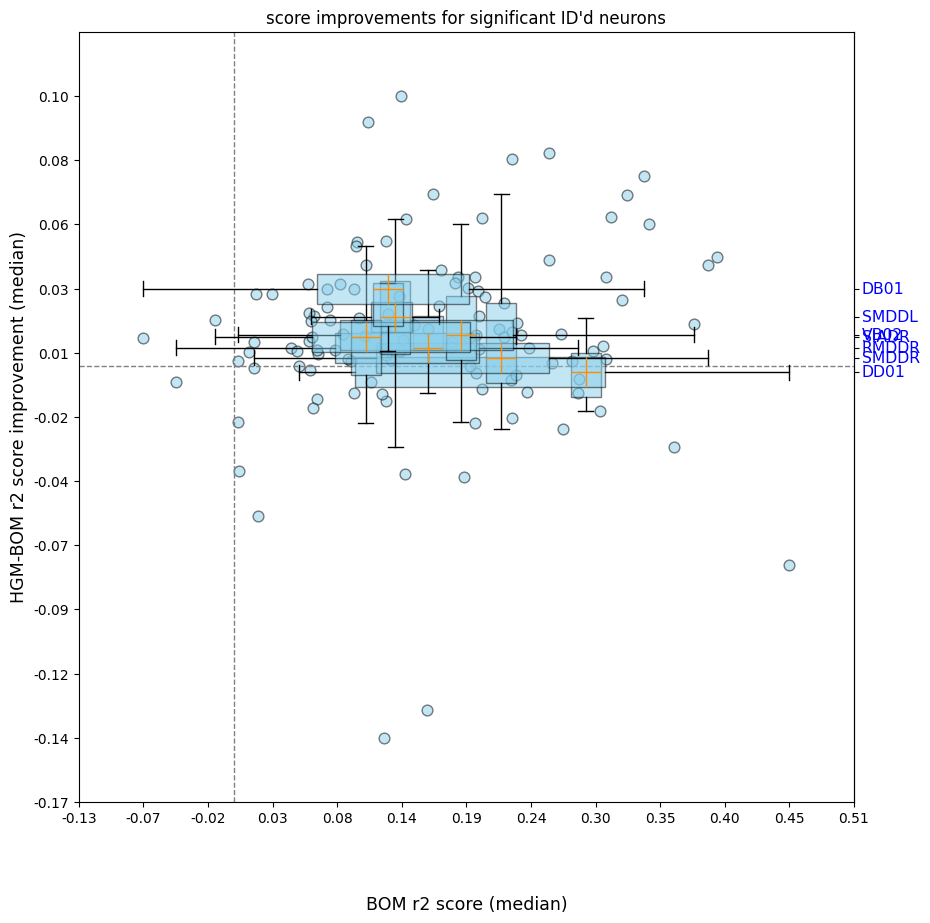

In [16]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp_hgm_sig_labels if not key[0].isdigit()}, None,
		title='score improvements for significant ID\'d neurons', limits=None
	)

In [17]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	neuron_impros_gcamp_hgm_sig = list(reversed(sorted(neuron_scores_gcamp_hgm_sig, key=lambda x: np.median(x[1][1] - x[1][0]))))
	neuron_impros_gcamp_hgm_rel_labels = list([val[0] for val in neuron_impros_gcamp_hgm_sig])

	print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_gcamp_hgm_sig if not key[0].isdigit()]))

NEURON: DB01,		IMPR: 0.0300
NEURON: SMDDL,		IMPR: 0.0191
NEURON: VB02,		IMPR: 0.0121
NEURON: SIADR,		IMPR: 0.0114
NEURON: RMDDR,		IMPR: 0.0072
NEURON: SMDDR,		IMPR: 0.0033
NEURON: DD01,		IMPR: -0.0024


In [18]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_gcamp_hgm_rel_labels if not label[0].isdigit()]))

Neuron names for copying:
'DB01', 'SMDDL', 'VB02', 'SIADR', 'RMDDR', 'SMDDR', 'DD01'
